In [27]:
import pandas as pd
import numpy as np
import sklearn
import os
import seaborn as sns
import matplotlib.pyplot as plt
import math

### Data Cleaning

In [28]:
# Data Cleaning
data_set = pd.read_csv('../data/ai_human_content_detection_dataset.csv')
print(f'Samples: {len(data_set)}')
cols = list(data_set.columns)
print(cols)
print(data_set.isna().sum())

Samples: 1367
['text_content', 'content_type', 'word_count', 'character_count', 'sentence_count', 'lexical_diversity', 'avg_sentence_length', 'avg_word_length', 'punctuation_ratio', 'flesch_reading_ease', 'gunning_fog_index', 'grammar_errors', 'passive_voice_ratio', 'predictability_score', 'burstiness', 'sentiment_score', 'label']
text_content             0
content_type             0
word_count               0
character_count          0
sentence_count           0
lexical_diversity        0
avg_sentence_length      0
avg_word_length          0
punctuation_ratio        0
flesch_reading_ease     79
gunning_fog_index       35
grammar_errors           0
passive_voice_ratio     31
predictability_score     0
burstiness               0
sentiment_score         54
label                    0
dtype: int64


In [29]:
# Apply median imputation (all columns will missing values are continuous numeric values)
for c in cols:
    if data_set[c].isna().sum():
        med = data_set[c].median()
        data_set[c] = data_set[c].fillna(med)

In [30]:
missing = 0
for c in cols:
    missing += data_set[c].isna().sum()
print(f'Missing Values in data_set: {missing}')
data_set.to_csv('../data/clean_data.csv', index=False)

Missing Values in data_set: 0


### Data Preprossesing

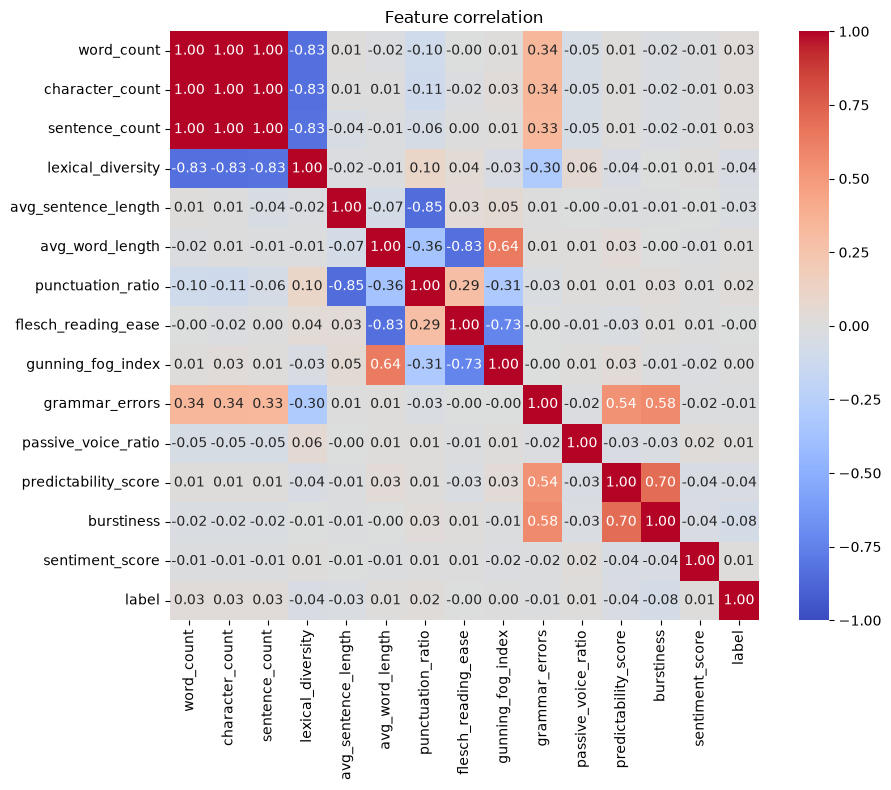

In [31]:
data_set = pd.read_csv('../data/clean_data.csv')

def plot_correlation(data):
    data = data.select_dtypes(include='number')
    corr = data.corr(numeric_only=True)
    
    plt.figure(figsize=(10, 8))
    sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm",
                center=0, vmin=-1, vmax=1, square=True)
    plt.title("Feature correlation")
    plt.tight_layout()
    plt.show()
plot_correlation(data_set)

In [ ]:
# removing strongly correlated features to reduce niose (drop: flesch_reading_index, sentance_count, word_count)
data_set = data_set.drop(['flesch_reading_index, sentance_count, word_count'])

